<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">Minería de Datos · Proyecto Final</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">Los tres finalistas: sistema 3, E3 y E4</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Miguel A. Garcia, Nadia Ramos, Ángel J. Zamora</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

**Dónde estamos.** De los 30 sistemas evaluados en el proyecto (`resumen_proyecto.ipynb`), tres quedaron como finalistas:

| Finalista | Qué es | Por qué es finalista | Advertencia |
|:--|:--|:--|:--|
| **3. Stacking LR + BETO** | Regresión logística sobre las probabilidades de la LR de texto y de BETO | El elegido por el protocolo: el mejor en CV de los sistemas fijados antes de su test | — |
| **E3. Stacking con pesos no negativos** | Regresión logística con pesos ≥ 0 sobre las probabilidades de 12 bases (incluidos BETO y BERTIN) | El mejor en CV de todo el proyecto junto con E4 | Diseñado después de ver el test; su CV se apoya en BERTIN, cuya CV es optimista |
| **E4. E3 + umbral anidado** | El mismo modelo que E3, con el corte de decisión elegido en CV en lugar de 0.5 | El más alto de los exploratorios en el test | Igual que E3 |

**Para dónde vamos.** Documentamos a fondo los tres: métricas completas en CV y en el test, matrices de confusión, qué pasó durante el entrenamiento (pérdida por época de los transformers, pérdida del optimizador de cada meta-modelo, búsqueda de `C` y del umbral), **qué aporta cada base** (valores SHAP exactos) y **qué palabras empujan cada predicción** (LIME de punta a punta y SHAP exacto de la LR de texto).

**Fuentes.** Las entradas y parámetros de los meta-modelos los guardó `ensamble_beto.ipynb` (`finalistas_entradas.csv`, `finalistas_meta.json`); aquí se vuelven a ajustar y se verifica que den lo mismo. LIME lo calcula `finalistas_lime.py` en la GPU (reentrena las bases con las 961 noticias, porque el proyecto no guarda pesos). El test ya se había visto: este notebook solo analiza, no elige nada.

## Contenido

* [Sección 0: Configuración](#seccion-0)
* **[Desempeño](#fase-desempeno)**
    * [Sección 1: Métricas en CV](#seccion-1)
    * [Sección 2: Métricas en el test y comparaciones](#seccion-2)
    * [Sección 3: Matrices de confusión](#seccion-3)
* **[Entrenamiento](#fase-entrenamiento)**
    * [Sección 4: Las bases transformer: pérdida por época](#seccion-4)
    * [Sección 5: Los meta-modelos: búsqueda de C, pérdida del optimizador y pesos](#seccion-5)
    * [Sección 6: El umbral de E4](#seccion-6)
* **[Interpretación](#fase-interpretacion)**
    * [Sección 7: Qué aporta cada base (SHAP exacto)](#seccion-7)
    * [Sección 8: Qué palabras empujan cada predicción (LIME y SHAP de la LR)](#seccion-8)
* **[Conclusiones](#conclusiones)**
    * [Sección 9: ¿Cuál elegir?](#seccion-9)
    * [Sección 10: Referencias](#seccion-10)

<a id="seccion-0"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 0: Configuración</span></div>

> **Qué se hace:** cargamos bibliotecas, constantes y los resultados guardados.
>
> **Qué se espera ver:** 961 filas de CV y 572 del test, con las probabilidades de las 12 bases y de los finalistas.

### 0.1 Bibliotecas

In [1]:
# Manejo de datos
import json
import os
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt

# Modelado y evaluación
from scipy import stats
from scipy.optimize import minimize
from sklearn.metrics import confusion_matrix

# Funciones compartidas del proyecto
import utils_fakedes as uf
from utils_fakedes import guardar, guardar_csv

### 0.2 Constantes

In [2]:
SEMILLA = uf.SEMILLA
TINTA, TINTA_SUAVE = uf.TINTA, uf.TINTA_SUAVE
N_BOOTSTRAP = 1000
OFICIALES = {'Baseline BoW + SVM': 0.7217, 'Baseline BETO': 0.7321, '1.er lugar (GDUFS_DM)': 0.7666}
REJILLA_META = [0.01, 0.1, 1, 10, 100]
UMBRALES = np.round(np.arange(0.20, 0.705, 0.01), 2)
FINALISTAS = ['3. Stacking LR + BETO', 'E3. Pesos no negativos', 'E4. E3 + umbral anidado']
COLOR = {'3. Stacking LR + BETO': '#3D6FB0', 'E3. Pesos no negativos': '#c9a227', 'E4. E3 + umbral anidado': '#8c6d1f'}
uf.configurar_graficas()
uf.crear_carpetas(uf.RUTA_RESULTADOS, uf.RUTA_FIGURAS)

### 0.3 Datos

In [3]:
entradas = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, 'finalistas_entradas.csv'))
with open(os.path.join(uf.RUTA_RESULTADOS, 'finalistas_meta.json'), encoding = 'utf-8') as f:
    meta = json.load(f)
cv = entradas[entradas['conjunto'] == 'cv'].reset_index(drop = True)
prueba = entradas[entradas['conjunto'] == 'test'].reset_index(drop = True)
BASES = meta['bases_E3']
ENTRADAS_3 = meta['sistema_3']['entradas']
y = cv['Category'].values
y_num = (y == 'Fake').astype(int)
folds = cv['fold_grupo'].values
y_test = prueba['Category'].values
previas = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, 'predicciones_test_umbral.csv')).set_index('id_unico').loc[prueba['id_unico']]

def clases(prob, umbral = 0.5):
    '''
    Función que convierte probabilidades de fake en clases

    inputs:
    --------
        prob (array-like): Probabilidades de 'Fake'
        umbral (float): Valor de corte

    outputs:
    --------
        numpy.ndarray: 'Fake' si prob >= umbral; 'True' en otro caso
    '''
    return np.where(np.asarray(prob) >= umbral, 'Fake', 'True')

pred_cv = {'3. Stacking LR + BETO': clases(cv['prob 3']), 'E3. Pesos no negativos': clases(cv['prob E3']),
           'E4. E3 + umbral anidado': cv['pred E4'].values}
pred_test = {'3. Stacking LR + BETO': clases(prueba['prob 3']), 'E3. Pesos no negativos': clases(prueba['prob E3']),
             'E4. E3 + umbral anidado': prueba['pred E4'].values,
             'LR texto (principal)': previas['LR texto (principal)'].values, 'LR texto, umbral 0.34': previas['LR texto, umbral 0.34'].values}
print(f'CV: {len(cv)} noticias; test: {len(prueba)}; bases de E3: {len(BASES)}; umbral de E4 en el test: {meta["E4"]["umbral_test"]}')

CV: 961 noticias; test: 572; bases de E3: 12; umbral de E4 en el test: 0.44


<a id="fase-desempeno"></a>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Desempeño</span></div>

<a id="seccion-1"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 1: Métricas en CV</span></div>

> **Qué se hace:** calculamos todas las métricas de los tres finalistas en cada fold (esquema B para los meta-modelos; umbral anidado para E4).
>
> **Qué se espera ver:** F1 de fake alrededor de 0.75 para el sistema 3 y 0.81 para E3 y E4, con el fold de la sátira como el más difícil para el 3.

#### Glosario de la sección
* **Precisión de fake:** de las noticias que el sistema marca como falsas, qué fracción lo es.
* **Exhaustividad (*recall*) de fake:** de las noticias falsas, qué fracción detecta.
* **F1 de fake:** media armónica de las dos; es la métrica oficial.
* **Macro-F1:** promedio de la F1 de fake y la F1 de verdaderas.

**Tabla 1.1.** Todas las métricas en CV, fold por fold, de los tres finalistas.

In [4]:
filas = []
for nombre in FINALISTAS:
    for k in range(5):
        en_k = folds == k
        fila = {'finalista': nombre, 'fold': k}
        fila.update(uf.metricas(y[en_k], pred_cv[nombre][en_k]))
        filas.append(fila)
metricas_cv = pd.DataFrame(filas)
guardar_csv(metricas_cv, 'finalistas_metricas_cv')
metricas_cv.round(4)

,finalista,fold,F1_fake,F1_true,F1_macro,accuracy,precision_fake,recall_fake
0,3. Stacking LR + BETO,0,0.8110,0.7692,0.7901,0.7922,0.8583,0.7687
1,3. Stacking LR + BETO,1,0.6842,0.7895,0.7368,0.7474,0.8814,0.5591
2,3. Stacking LR + BETO,2,0.7722,0.8235,0.7978,0.8011,0.8133,0.7349
3,3. Stacking LR + BETO,3,0.6923,0.7647,0.7285,0.7333,0.7297,0.6585
4,3. Stacking LR + BETO,4,0.7719,0.7914,0.7817,0.7821,0.7416,0.8049
5,E3. Pesos no negativos,0,0.8201,0.7283,0.7742,0.7835,0.7917,0.8507
6,E3. Pesos no negativos,1,0.9043,0.9062,0.9053,0.9053,0.8947,0.9140
7,E3. Pesos no negativos,2,0.7922,0.8462,0.8192,0.8232,0.8592,0.7349
8,E3. Pesos no negativos,3,0.7534,0.8318,0.7926,0.8000,0.8594,0.6707
9,E3. Pesos no negativos,4,0.7879,0.8187,0.8033,0.8045,0.7831,0.7927


**Tabla 1.2.** Media ± sd de los 5 folds.

In [5]:
media = metricas_cv.drop(columns = 'fold').groupby('finalista', sort = False).mean()
sd = metricas_cv.drop(columns = 'fold').groupby('finalista', sort = False).std()
tabla = media.round(4).astype(str) + ' ± ' + sd.round(4).astype(str)
tabla

,F1_fake,F1_true,F1_macro,accuracy,precision_fake,recall_fake
finalista,,,,,,
3. Stacking LR + BETO,0.7463 ± 0.0554,0.7877 ± 0.0233,0.767 ± 0.032,0.7712 ± 0.0294,0.8049 ± 0.0679,0.7052 ± 0.0979
E3. Pesos no negativos,0.8116 ± 0.057,0.8262 ± 0.0642,0.8189 ± 0.051,0.8233 ± 0.0479,0.8376 ± 0.0482,0.7926 ± 0.0953
E4. E3 + umbral anidado,0.813 ± 0.0596,0.8198 ± 0.0682,0.8164 ± 0.0541,0.8208 ± 0.051,0.8201 ± 0.0542,0.8098 ± 0.089


**Qué se observa.**

* **E3 y E4 superan al sistema 3 en CV:** 0.8116 ± 0.057 y 0.813 ± 0.0596 de F1 de fake, contra 0.7463 ± 0.0554 (Tabla 1.2). También en todas las demás métricas: macro-F1 0.8189 y 0.8164 contra 0.767.
* **La diferencia está en el fold de la sátira** (fold 1). El sistema 3 saca 0.6842 ahí y solo detecta el 55.9 % de las falsas (exhaustividad 0.5591). E3 y E4 sacan 0.9043, con exhaustividad 0.9140. Es el efecto de BERTIN, que reconoce el estilo de *El Ruinaversal*.
* **E4 solo se distingue de E3 por el umbral.** Gana en los folds 0 y 2 (0.8293 y 0.8000 contra 0.8201 y 0.7922) y pierde en el 3 (0.7436 contra 0.7534). Detecta más falsas (exhaustividad 0.8098 contra 0.7926) con menos precisión (0.8201 contra 0.8376).

**En CV, los finalistas exploratorios aventajan al sistema 3 por ≈ 0.065, casi todo por el fold de la sátira, que es justo donde BERTIN tiene ventaja de estilo (ver `ensamble_beto.ipynb`, Sección 12.4).**

<a id="seccion-2"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 2: Métricas en el test y comparaciones</span></div>

> **Qué se hace:** calculamos las métricas en el test con IC95 bootstrap (los mismos 1,000 remuestreos de todo el proyecto) y comparamos los finalistas entre sí y con el principal y el umbral 0.34.
>
> **Qué se espera ver:** tres sistemas en ≈ 0.74–0.76 sin diferencias significativas entre ellos.

**Tabla 2.1.** Métricas en el test con IC95 bootstrap de la F1 de fake.

In [6]:
rng = np.random.default_rng(SEMILLA)
indices_boot = rng.integers(0, len(prueba), size = (N_BOOTSTRAP, len(prueba)))

def f1_bootstrap(pred):
    '''
    Función que calcula la F1 de fake en cada remuestreo bootstrap del test

    inputs:
    --------
        pred (numpy.ndarray): Predicciones sobre el test

    outputs:
    --------
        numpy.ndarray: F1 de fake de cada remuestreo
    '''
    valores = []
    for i in indices_boot:
        valores.append(uf.f1_fake(y_test[i], pred[i]))
    return np.array(valores)

boot = {}
for nombre, pred in pred_test.items():
    boot[nombre] = f1_bootstrap(pred)
filas = []
for nombre, pred in pred_test.items():
    fila = {'sistema': nombre}
    for metrica, valor in uf.metricas(y_test, pred).items():
        fila[metrica] = round(valor, 4)
    fila['IC95 F1_fake'] = f'[{np.percentile(boot[nombre], 2.5):.3f}, {np.percentile(boot[nombre], 97.5):.3f}]'
    fila['predichas Fake'] = int((pred == 'Fake').sum())
    filas.append(fila)
metricas_test = pd.DataFrame(filas).set_index('sistema')
guardar_csv(metricas_test, 'finalistas_metricas_test', index = True)
metricas_test

,F1_fake,F1_true,F1_macro,accuracy,precision_fake,recall_fake,IC95 F1_fake,predichas Fake
sistema,,,,,,,,
3. Stacking LR + BETO,0.7357,0.7629,0.7493,0.7500,0.7804,0.6958,"[0.690, 0.778]",255
E3. Pesos no negativos,0.7496,0.7361,0.7428,0.7430,0.7309,0.7692,"[0.708, 0.789]",301
E4. E3 + umbral anidado,0.7550,0.7259,0.7404,0.7413,0.7170,0.7972,"[0.715, 0.794]",318
LR texto (principal),0.6764,0.7669,0.7217,0.7290,0.8394,0.5664,"[0.629, 0.722]",193
"LR texto, umbral 0.34",0.7346,0.6882,0.7114,0.7133,0.6837,0.7937,"[0.696, 0.771]",332


**Tabla 2.2.** Comparaciones pareadas en el test: diferencia de F1 de fake (IC95 bootstrap pareado) y McNemar exacta.

In [7]:
def comparar(a, b):
    '''
    Función que compara dos sistemas en el test con bootstrap pareado y McNemar exacta

    inputs:
    --------
        a (str): Sistema que se compara
        b (str): Sistema de referencia

    outputs:
    --------
        dict: Diferencia de F1, IC95 pareado, remuestreos en que gana a y McNemar
    '''
    dif = boot[a] - boot[b]
    ok_a = pred_test[a] == y_test
    ok_b = pred_test[b] == y_test
    solo_a = int((ok_a & ~ok_b).sum())
    solo_b = int((~ok_a & ok_b).sum())
    p = stats.binomtest(solo_a, solo_a + solo_b, 0.5).pvalue if solo_a + solo_b > 0 else 1.0
    return {'sistema': a, 'referencia': b,
            'diferencia F1 fake': round(uf.f1_fake(y_test, pred_test[a]) - uf.f1_fake(y_test, pred_test[b]), 3),
            'IC95 pareado': f'[{np.percentile(dif, 2.5):+.3f}, {np.percentile(dif, 97.5):+.3f}]',
            'remuestreos en que gana': f'{int((dif > 0).sum())} de {N_BOOTSTRAP}',
            'McNemar (solo a / solo b)': f'{solo_a} / {solo_b}', 'p McNemar': round(p, 3)}

pares = [('E3. Pesos no negativos', '3. Stacking LR + BETO'), ('E4. E3 + umbral anidado', '3. Stacking LR + BETO'),
         ('E4. E3 + umbral anidado', 'E3. Pesos no negativos')]
for nombre in FINALISTAS:
    pares.append((nombre, 'LR texto (principal)'))
    pares.append((nombre, 'LR texto, umbral 0.34'))
filas = []
for a, b in pares:
    filas.append(comparar(a, b))
comparaciones = pd.DataFrame(filas)
guardar_csv(comparaciones, 'finalistas_comparaciones')
comparaciones

,sistema,referencia,diferencia F1 fake,IC95 pareado,remuestreos en que gana,McNemar (solo a / solo b),p McNemar
0,E3. Pesos no negativos,3. Stacking LR + BETO,0.014,"[-0.025, +0.050]",774 de 1000,44 / 48,0.755
1,E4. E3 + umbral anidado,3. Stacking LR + BETO,0.019,"[-0.019, +0.056]",855 de 1000,48 / 53,0.691
2,E4. E3 + umbral anidado,E3. Pesos no negativos,0.005,"[-0.007, +0.020]",798 de 1000,8 / 9,1.000
3,3. Stacking LR + BETO,LR texto (principal),0.059,"[+0.020, +0.100]",998 de 1000,53 / 41,0.256
4,3. Stacking LR + BETO,"LR texto, umbral 0.34",0.001,"[-0.038, +0.038]",529 de 1000,72 / 51,0.071
5,E3. Pesos no negativos,LR texto (principal),0.073,"[+0.024, +0.122]",997 de 1000,73 / 65,0.551
6,E3. Pesos no negativos,"LR texto, umbral 0.34",0.015,"[-0.020, +0.050]",803 de 1000,67 / 50,0.139
7,E4. E3 + umbral anidado,LR texto (principal),0.079,"[+0.029, +0.125]",998 de 1000,80 / 73,0.628
8,E4. E3 + umbral anidado,"LR texto, umbral 0.34",0.020,"[-0.014, +0.053]",877 de 1000,66 / 50,0.163


**Figura 2.1.** F1 de fake en el test con IC95 de los finalistas y las dos referencias; las líneas son los resultados oficiales.

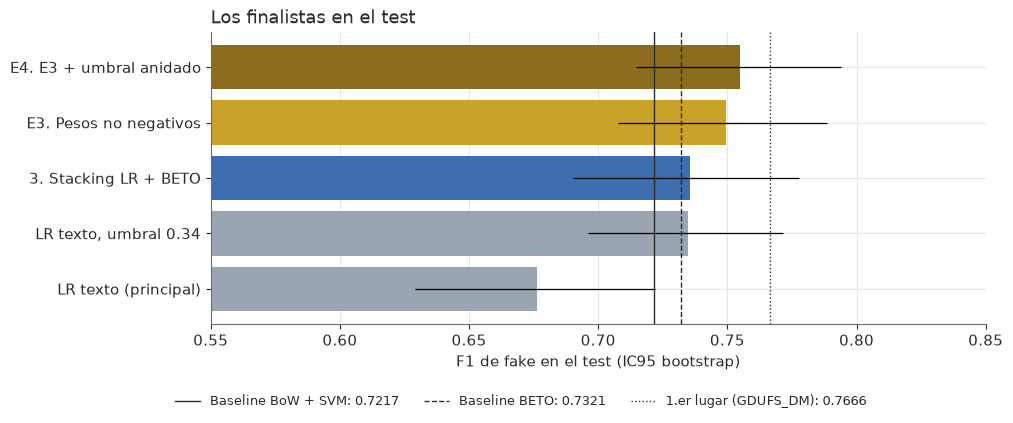

In [8]:
orden = ['LR texto (principal)', 'LR texto, umbral 0.34'] + FINALISTAS
fig, ax = plt.subplots(figsize = (10, 3.8))
for i, nombre in enumerate(orden):
    valor = metricas_test.loc[nombre, 'F1_fake']
    error = [[valor - np.percentile(boot[nombre], 2.5)], [np.percentile(boot[nombre], 97.5) - valor]]
    ax.barh(i, valor, xerr = error, color = COLOR.get(nombre, '#9aa5b1'), error_kw = {'lw': 0.9})
ax.set_yticks(range(len(orden)), orden)
for (etiqueta, valor), estilo in zip(OFICIALES.items(), ['-', '--', ':']):
    ax.axvline(valor, color = TINTA, linestyle = estilo, linewidth = 1, label = f'{etiqueta}: {valor:.4f}')
ax.set_xlim(0.55, 0.85)
ax.set_xlabel('F1 de fake en el test (IC95 bootstrap)')
ax.set_title('Los finalistas en el test')
ax.legend(loc = 'upper center', bbox_to_anchor = (0.4, -0.2), ncol = 3, fontsize = 9)
guardar(fig, '2_1_finalistas_f1_test')
plt.show()

**Qué se observa.**

* **En el test, los tres quedan juntos:** sistema 3 0.7357 (IC95 [0.690, 0.778]), E3 0.7496 ([0.708, 0.789]) y E4 0.7550 ([0.715, 0.794]).
* **Ninguna diferencia entre finalistas es significativa** (Tabla 2.2):
  * E3 − sistema 3: +0.014 (IC [−0.025, +0.050], McNemar p = 0.755);
  * E4 − sistema 3: +0.019 (IC [−0.019, +0.056], p = 0.691);
  * E4 − E3: +0.005 (IC [−0.007, +0.020]); difieren en solo 17 noticias (8 contra 9, p = 1.000).
* **Los tres superan al principal** con IC pareado que excluye el 0 (+0.059, +0.073 y +0.079) y **empatan con el umbral 0.34** (+0.001, +0.015 y +0.020).
* **Cada uno acomoda el balance de otra forma:**

  | Finalista | Falsas marcadas | Exhaustividad | Precisión | Exactitud |
  |:--|--:|--:|--:|--:|
  | Sistema 3 | 255 | 0.6958 | 0.7804 | 0.7500 |
  | E3 | 301 | 0.7692 | 0.7309 | 0.7430 |
  | E4 | 318 | 0.7972 | 0.7170 | 0.7413 |

  El sistema 3 es el más preciso y el que más noticias acierta en total. E4 es el que más falsas detecta.

**La ventaja de E3 y E4 en CV (+0.065) se reduce a +0.014 y +0.019 en el test, sin significancia. Los tres son igual de buenos en F1 de fake; cambian en cuántas falsas alarmas aceptan.**

<a id="seccion-3"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 3: Matrices de confusión</span></div>

> **Qué se hace:** dibujamos la matriz de confusión de cada finalista en CV (las 961 noticias) y en el test (572), con proporción por fila y conteos.
>
> **Qué se espera ver:** que E4 detecte más falsas que E3 (umbral más bajo) a cambio de más falsas alarmas.

**Figura 3.1.** Matrices de confusión: CV arriba, test abajo.

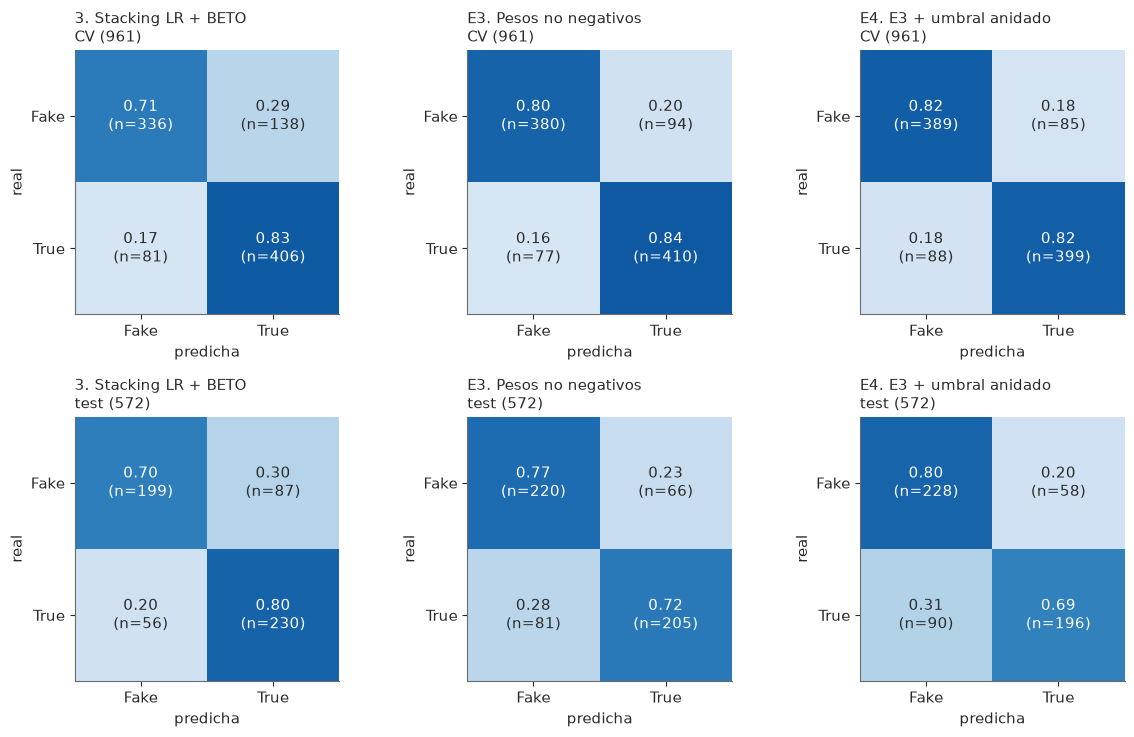

In [9]:
def dibujar_matriz(ax, y_real, y_pred, titulo):
    '''
    Función que dibuja una matriz de confusión con proporción por fila y conteos

    inputs:
    --------
        ax (matplotlib.axes.Axes): Eje
        y_real (array-like): Clases reales
        y_pred (array-like): Clases predichas
        titulo (str): Título

    outputs:
    --------
        None
    '''
    etiquetas = ['Fake', 'True']
    cm = confusion_matrix(y_real, y_pred, labels = etiquetas)
    cm_norm = cm / cm.sum(axis = 1, keepdims = True)
    ax.imshow(cm_norm, cmap = 'Blues', vmin = 0, vmax = 1)
    for i in range(2):
        for j in range(2):
            color = 'white' if cm_norm[i, j] > 0.5 else TINTA
            ax.text(j, i, f'{cm_norm[i, j]:.2f}\n(n={cm[i, j]})', ha = 'center', va = 'center', color = color, fontsize = 11)
    ax.set_xticks([0, 1], etiquetas)
    ax.set_yticks([0, 1], etiquetas)
    ax.set_xlabel('predicha')
    ax.set_ylabel('real')
    ax.set_title(titulo, fontsize = 11)
    ax.grid(False)

fig, ejes = plt.subplots(2, 3, figsize = (12, 7.5))
for j, nombre in enumerate(FINALISTAS):
    dibujar_matriz(ejes[0, j], y, pred_cv[nombre], f'{nombre}\nCV (961)')
    dibujar_matriz(ejes[1, j], y_test, pred_test[nombre], f'{nombre}\ntest (572)')
fig.tight_layout()
guardar(fig, '3_1_finalistas_matrices')
plt.show()

**Qué se observa.**

* **En CV (arriba), E3 tiene menos errores que el sistema 3 en las dos clases:** 94 falsas sin detectar contra 138 y 77 falsas alarmas contra 81. E4 baja todavía más las falsas sin detectar (85), pero a cambio sube las falsas alarmas (88).
* **En el test (abajo), los tres cambian falsas no detectadas por falsas alarmas:**
  * el sistema 3 marca 255 noticias como falsas, E3 301 y E4 318 (Tabla 2.1);
  * cada paso detecta más falsas reales, pero también marca más verdaderas como falsas.
* Ninguno tiene una fila "buena" en las dos clases a la vez: el test tiene 286 falsas y 286 verdaderas, y los tres marcan entre 255 y 318 como falsas.

**Las matrices confirman que, en el test, la diferencia entre finalistas es de balance entre clases, no de calidad general.**

<a id="fase-entrenamiento"></a>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Entrenamiento</span></div>

<a id="seccion-4"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 4: Las bases transformer: pérdida por época</span></div>

> **Qué se hace:** mostramos cómo bajó la pérdida de entrenamiento de BETO (en los tres finalistas) y de BERTIN (en E3 y E4) en cada fold, semilla y en el entrenamiento final con las 961 noticias.
>
> **Qué se espera ver:** pérdidas que bajan en las 4 épocas sin estancarse; BERTIN más abajo que BETO.

#### Glosario de la sección
* **Pérdida de entrenamiento (entropía cruzada):** qué tan lejos están las probabilidades del modelo de las etiquetas reales en las noticias de entrenamiento. Baja mientras el modelo aprende; si llega a casi 0, puede estar memorizando.

**Figura 4.1.** Pérdida por época de BETO y BERTIN (cada línea es un fold con una semilla; en rojo, los entrenamientos con las 961 noticias que predicen el test).

BETO: pérdida de la última época de 0.058 a 0.112; 75 min de GPU en 18 entrenamientos
BERTIN: pérdida de la última época de 0.027 a 0.185; 68 min de GPU en 18 entrenamientos


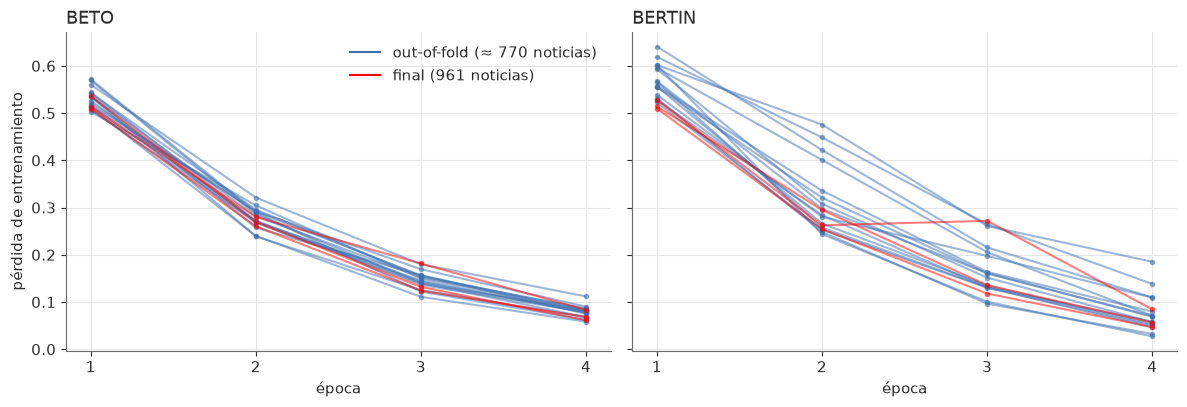

In [10]:
fig, ejes = plt.subplots(1, 2, figsize = (12, 4.2), sharey = True)
for ax, (nombre, archivo) in zip(ejes, [('BETO', 'beto_log.csv'), ('BERTIN', 'bertin_log.csv')]):
    log = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, archivo), dtype = {'fold': str})
    for i in range(len(log)):
        fila = log.iloc[i]
        perdidas = [fila['perdida_epoca_1'], fila['perdida_epoca_2'], fila['perdida_epoca_3'], fila['perdida_epoca_4']]
        color = 'red' if fila['fold'] == 'test' else '#3D6FB0'
        ax.plot([1, 2, 3, 4], perdidas, color = color, alpha = 0.5, marker = 'o', markersize = 3)
    print(f'{nombre}: pérdida de la última época de {log["perdida_final"].min():.3f} a {log["perdida_final"].max():.3f}; '
          f'{log["minutos"].sum():.0f} min de GPU en 18 entrenamientos')
    ax.set_title(nombre)
    ax.set_xticks([1, 2, 3, 4])
    ax.set_xlabel('época')
ejes[0].set_ylabel('pérdida de entrenamiento')
ejes[0].plot([], [], color = '#3D6FB0', label = 'out-of-fold (≈ 770 noticias)')
ejes[0].plot([], [], color = 'red', label = 'final (961 noticias)')
ejes[0].legend()
fig.tight_layout()
guardar(fig, '4_1_finalistas_perdida_transformers')
plt.show()

**Qué se observa.**

* **Las dos bases transformer entrenan bien:** la pérdida baja en las 4 épocas en todos los folds y semillas, sin estancarse ni subir.
* **BERTIN termina más abajo** (pérdida final de 0.027 a 0.185) que BETO (0.058 a 0.112), con una dispersión mayor entre entrenamientos. Su pérdida casi en 0 en algunos casos es coherente con que ya conocía el estilo de parte del corpus.
* **El costo:** 75 min de GPU para los 18 entrenamientos de BETO y 68 para los de BERTIN.

**Ninguna curva muestra problemas de entrenamiento; la diferencia entre BETO y BERTIN no viene de un entrenamiento fallido, sino de lo que cada uno sabía antes del ajuste fino.**

<a id="seccion-5"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 5: Los meta-modelos: búsqueda de C, pérdida del optimizador y pesos</span></div>

> **Qué se hace:** volvemos a ajustar los dos meta-modelos (el del sistema 3 y el de E3/E4) con su propio optimizador para registrar la pérdida en cada iteración, verificamos que den los mismos pesos que en `ensamble_beto.ipynb` y mostramos la búsqueda de `C` y los pesos por fold.
>
> **Qué se espera ver:** que el optimizador converja en pocas iteraciones (son modelos de 2 y 12 entradas) y que los pesos coincidan con los guardados.

#### Glosario de la sección
* **Pérdida logística regularizada:** lo que minimiza el meta-modelo: `C × Σ peso_clase × log-pérdida + ½ ‖w‖²`. El primer término mide qué tan mal predice; el segundo castiga pesos grandes (regularización L2).
* **L-BFGS:** el optimizador que usan `LogisticRegression` y `scipy.optimize.minimize`. Cada iteración mueve los pesos en la dirección que baja la pérdida.
* **Pesos no negativos:** en E3 los pesos tienen que ser ≥ 0 (el optimizador los acota con `bounds`); una base que no ayuda queda en 0.

In [11]:
def ajustar_logistica(X, y_numerica, c, no_negativa):
    '''
    Función que ajusta una regresión logística con pesos de clase balanceados y L2, y registra la pérdida por iteración

    inputs:
    --------
        X (numpy.ndarray): Entradas
        y_numerica (numpy.ndarray): 1 = Fake, 0 = True
        c (float): Inverso de la regularización (como el C de scikit-learn)
        no_negativa (bool): Si los pesos se acotan a ser ≥ 0

    outputs:
    --------
        tuple: (pesos, intercepto, pérdida en cada iteración)
    '''
    n_fake = y_numerica.sum()
    n_true = len(y_numerica) - n_fake
    peso_fila = np.where(y_numerica == 1, len(y_numerica) / (2 * n_fake), len(y_numerica) / (2 * n_true))
    p = X.shape[1]

    def perdida(theta):
        z = X @ theta[:p] + theta[p]
        valor = c * np.sum(peso_fila * (y_numerica * np.logaddexp(0, -z) + (1 - y_numerica) * np.logaddexp(0, z))) + 0.5 * np.sum(theta[:p] ** 2)
        residuo = c * peso_fila * (1 / (1 + np.exp(-z)) - y_numerica)
        return valor, np.concatenate([X.T @ residuo + theta[:p], [residuo.sum()]])

    historia = []

    def anotar(theta):
        historia.append(perdida(theta)[0])

    limites = None
    if no_negativa:
        limites = [(0, None)] * p + [(None, None)]
    inicial = np.zeros(p + 1)
    historia.append(perdida(inicial)[0])
    resultado = minimize(perdida, inicial, jac = True, method = 'L-BFGS-B', bounds = limites, callback = anotar,
                         options = {'maxiter': 2000, 'gtol': 1e-10, 'ftol': 1e-14})
    return resultado.x[:p], resultado.x[p], historia

def prob_logistica(pesos, intercepto, X):
    '''
    Función que calcula la probabilidad de fake de una regresión logística

    inputs:
    --------
        pesos (numpy.ndarray): Pesos
        intercepto (float): Intercepto
        X (numpy.ndarray): Entradas

    outputs:
    --------
        numpy.ndarray: Probabilidad de fake
    '''
    return 1 / (1 + np.exp(-(X @ pesos + intercepto)))

X3 = cv[ENTRADAS_3].values
X_e3 = cv[BASES].values
pesos_3, intercepto_3, historia_3 = ajustar_logistica(X3, y_num, meta['sistema_3']['C'], False)
pesos_e3, intercepto_e3, historia_e3 = ajustar_logistica(X_e3, y_num, meta['E3']['C'], True)
verificacion = pd.DataFrame([
    ('Sistema 3: pesos iguales a los de ensamble_beto (tolerancia 0.05: scikit-learn detiene su optimizador antes, con tol = 1e-4)', bool(np.allclose(pesos_3, meta['sistema_3']['pesos'], atol = 0.05)),
     float(np.max(np.abs(pesos_3 - np.array(meta['sistema_3']['pesos']))))),
    ('E3: pesos iguales a los de ensamble_beto (tolerancia 0.01)', bool(np.allclose(pesos_e3, meta['E3']['pesos'], atol = 0.01)),
     float(np.max(np.abs(pesos_e3 - np.array(meta['E3']['pesos']))))),
    ('Sistema 3: probabilidades del test iguales a las guardadas', bool(np.allclose(prob_logistica(pesos_3, intercepto_3, prueba[ENTRADAS_3].values), prueba['prob 3'], atol = 0.005)),
     float(np.max(np.abs(prob_logistica(pesos_3, intercepto_3, prueba[ENTRADAS_3].values) - prueba['prob 3'])))),
    ('E3: probabilidades del test iguales a las guardadas', bool(np.allclose(prob_logistica(pesos_e3, intercepto_e3, prueba[BASES].values), prueba['prob E3'], atol = 0.005)),
     float(np.max(np.abs(prob_logistica(pesos_e3, intercepto_e3, prueba[BASES].values) - prueba['prob E3'])))),
], columns = ['verificación', 'cumple', 'diferencia máxima'])
verificacion['estado'] = np.where(verificacion['cumple'], '✅', '❌')
verificacion

,verificación,cumple,diferencia máxima,estado
0,Sistema 3: pesos iguales a los de ensamble_bet...,True,0.014536,✅
1,E3: pesos iguales a los de ensamble_beto (tole...,True,0.000338,✅
2,Sistema 3: probabilidades del test iguales a l...,True,0.001092,✅
3,E3: probabilidades del test iguales a las guar...,True,0.000035,✅


**Tabla 5.1.** Búsqueda de `C` con los 5 folds (F1 de fake media): sistema 3 (de `ensamble_beto.ipynb`) y E3 (recalculada aquí).

In [12]:
grid_3 = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, 'beto_meta_grid.csv'))
grid_3 = grid_3[(grid_3['sistema'] == '3. Stacking LR (LR + BETO)') & grid_3['ajuste'].str.startswith('todo')]
filas = []
for c in REJILLA_META:
    valores = []
    for k in range(5):
        en_k = folds == k
        pesos, intercepto, _ = ajustar_logistica(X_e3[~en_k], y_num[~en_k], c, True)
        valores.append(uf.f1_fake(y[en_k], clases(prob_logistica(pesos, intercepto, X_e3[en_k]))))
    filas.append({'C': c, 'sistema 3': float(grid_3.loc[grid_3['C'] == c, 'F1_fake_media'].iloc[0]), 'E3 (pesos no negativos)': np.mean(valores)})
print(f'C elegida: sistema 3 = {meta["sistema_3"]["C"]}; E3 = {meta["E3"]["C"]}')
pd.DataFrame(filas).round(4)

C elegida: sistema 3 = 10.0; E3 = 1.0


,C,sistema 3,E3 (pesos no negativos)
0,0.01,0.7154,0.7989
1,0.10,0.7325,0.8132
2,1.00,0.7445,0.8147
3,10.00,0.7497,0.8120
4,100.00,0.7457,0.8123


**Figura 5.1.** Pérdida del optimizador en cada iteración al ajustar cada meta-modelo con todo el *out-of-fold* (escala logarítmica en el eje vertical).

3. Stacking LR + BETO (2 entradas): 14 iteraciones; pérdida inicial 6661.1, final 4480.3
E3 / E4 (12 entradas, pesos ≥ 0): 44 iteraciones; pérdida inicial 666.1, final 381.6


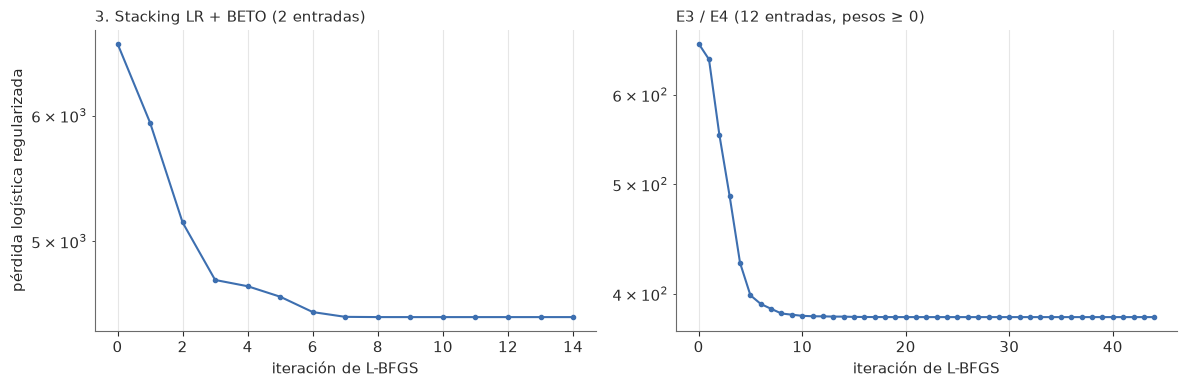

In [13]:
fig, ejes = plt.subplots(1, 2, figsize = (12, 4))
for ax, nombre, historia in [(ejes[0], '3. Stacking LR + BETO (2 entradas)', historia_3), (ejes[1], 'E3 / E4 (12 entradas, pesos ≥ 0)', historia_e3)]:
    ax.plot(range(len(historia)), historia, marker = 'o', markersize = 3, color = '#3D6FB0')
    ax.set_yscale('log')
    ax.set_xlabel('iteración de L-BFGS')
    ax.set_title(nombre, fontsize = 11)
    print(f'{nombre}: {len(historia) - 1} iteraciones; pérdida inicial {historia[0]:.1f}, final {historia[-1]:.1f}')
ejes[0].set_ylabel('pérdida logística regularizada')
fig.tight_layout()
guardar(fig, '5_1_finalistas_perdida_meta')
plt.show()

**Tabla 5.2.** Pesos de los meta-modelos: con todo el *out-of-fold* (los que se aplican al test) y en cada fold externo del esquema B.

In [14]:
columnas = {'todo el out-of-fold': list(pesos_e3) + [intercepto_e3]}
for k in range(5):
    dentro = folds != k
    pesos, intercepto, _ = ajustar_logistica(X_e3[dentro], y_num[dentro], meta['E3']['C'], True)
    columnas[f'fold externo {k}'] = list(pesos) + [intercepto]
pesos_tabla = pd.DataFrame(columnas, index = BASES + ['intercepto'])
pesos_3_tabla = pd.DataFrame({'todo el out-of-fold': list(pesos_3) + [intercepto_3]}, index = ENTRADAS_3 + ['intercepto'])
print('Sistema 3:')
display(pesos_3_tabla.round(3))
print('E3 / E4:')
pesos_tabla.round(3)

Sistema 3:


,todo el out-of-fold
LR texto,5.113
BETO,2.582
intercepto,-3.052


E3 / E4:


,todo el out-of-fold,fold externo 0,fold externo 1,fold externo 2,fold externo 3,fold externo 4
LR texto,1.068,0.424,0.000,1.249,1.320,1.214
XGBoost,1.158,0.592,1.037,1.118,1.174,1.366
RF estilo,0.000,0.000,0.000,0.000,0.000,0.000
BETO,0.713,0.420,1.174,0.683,0.781,0.629
HistGradientBoosting (caracteres),0.884,0.771,1.174,0.794,0.817,0.774
XGBoost (estilo),0.000,0.059,0.216,0.000,0.000,0.000
HistGradientBoosting (palabras + estilo),0.000,0.000,0.000,0.000,0.462,0.000
SVM-RBF (embeddings),0.440,0.741,0.344,0.335,0.378,0.393
kNN (embeddings),0.000,0.000,0.000,0.000,0.000,0.000
Naive Bayes (palabras),0.003,0.000,0.000,0.842,0.873,0.000


**Qué se observa.**

* **Los meta-modelos se reproducen** (verificación de arriba): los pesos de E3 coinciden con los de `ensamble_beto.ipynb` y las probabilidades del test de los dos finalistas también. Los del sistema 3 difieren un poco porque scikit-learn detiene su optimizador antes.
* **Búsqueda de `C`** (Tabla 5.1): para el sistema 3 va de 0.7154 a 0.7497 (se elige `C` = 10); para E3, de 0.7989 a 0.8147 (`C` = 1). Las dos curvas son bastante planas a partir de `C` = 0.1.
* **El optimizador converge rápido** (Figura 5.1): 14 iteraciones para el sistema 3 (la pérdida baja de 6661.1 a 4480.3) y 44 para E3 (de 666.1 a 381.6). La escala es distinta porque la pérdida se multiplica por `C`.
* **Pesos** (Tabla 5.2):
  * en el sistema 3, la LR pesa 5.113 y BETO 2.582;
  * en E3, BERTIN tiene el peso mayor (2.711), seguido de XGBoost (1.158), la LR (1.068), HistGradientBoosting de caracteres (0.884), BETO (0.713) y el SVM (0.440);
  * cinco bases quedan en 0: el bosque, XGBoost de estilo, HistGradientBoosting de palabras + estilo, el kNN y XLM-RoBERTa.
* **Por fold, BERTIN siempre es el peso más grande** (de 2.077 a 3.117). En el fold de la sátira, la LR queda en 0: ahí el meta-modelo confía en BERTIN. Naive Bayes entra y sale (0.842 y 0.873 en los folds 2 y 3, 0 en los demás), así que su aporte no es estable.

**El sistema 3 es un promedio ponderado simple de dos modelos. E3 es, sobre todo, BERTIN corregido por la LR, los boostings y BETO.**

<a id="seccion-6"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 6: El umbral de E4</span></div>

> **Qué se hace:** mostramos la curva de F1 de E3 según el umbral (con sus 961 predicciones del esquema B), los umbrales que eligió la CV anidada en cada fold y el umbral que se aplicó al test.
>
> **Qué se espera ver:** un máximo un poco abajo de 0.5 y umbrales anidados parecidos entre sí.

**Figura 6.1.** F1 de fake media por fold de E3 según el umbral. Línea punteada: 0.5 (E3); línea sólida: el umbral del test (E4); marcas grises: los umbrales de la CV anidada.

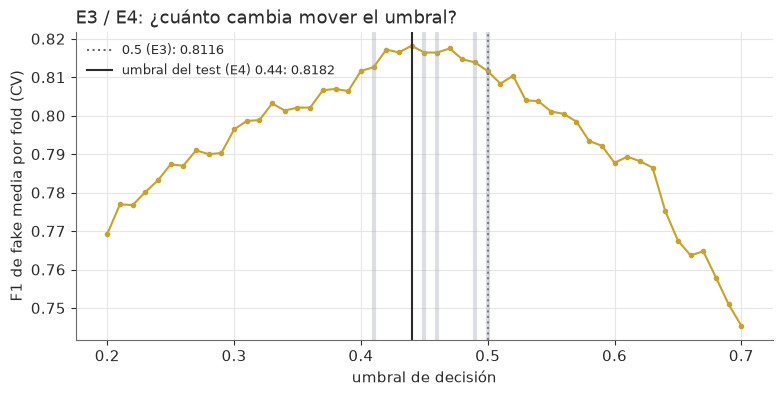

Umbrales de la CV anidada por fold: [0.45, 0.5, 0.46, 0.41, 0.49]; máximo de la curva en 0.44 (0.8182)


In [15]:
curva = []
for umbral in UMBRALES:
    valores = []
    for k in range(5):
        valores.append(uf.f1_fake(y[folds == k], clases(cv['prob E3'].values[folds == k], umbral)))
    curva.append(np.mean(valores))
curva = np.array(curva)
fig, ax = plt.subplots(figsize = (9, 4))
ax.plot(UMBRALES, curva, marker = 'o', markersize = 3, color = '#c9a227')
ax.axvline(0.5, color = TINTA_SUAVE, linestyle = ':', label = f'0.5 (E3): {curva[np.argmin(np.abs(UMBRALES - 0.5))]:.4f}')
ax.axvline(meta['E4']['umbral_test'], color = TINTA, label = f'umbral del test (E4) {meta["E4"]["umbral_test"]}: {curva[np.argmin(np.abs(UMBRALES - meta["E4"]["umbral_test"]))]:.4f}')
for umbral in meta['E4']['umbrales_por_fold']:
    ax.axvline(umbral, color = '#9aa5b1', linewidth = 3, alpha = 0.35)
ax.set_xlabel('umbral de decisión')
ax.set_ylabel('F1 de fake media por fold (CV)')
ax.set_title('E3 / E4: ¿cuánto cambia mover el umbral?')
ax.legend(fontsize = 9)
guardar(fig, '6_1_finalistas_umbral_e4')
plt.show()
print(f'Umbrales de la CV anidada por fold: {meta["E4"]["umbrales_por_fold"]}; máximo de la curva en {UMBRALES[np.argmax(curva)]} ({curva.max():.4f})')

**Qué se observa.**

* **La curva de E3 tiene su máximo justo en el umbral que se usa en el test** (0.44, con 0.8182), un poco abajo de 0.5. La CV anidada eligió umbrales de 0.41 a 0.50 según el fold: bastante estables.
* **El umbral apenas mueve la F1 en CV:** la curva es casi plana alrededor del máximo, en la misma zona donde caen los umbrales de la CV anidada. Por eso E4 y E3 casi no se distinguen (0.813 contra 0.8116 en CV; 0.7550 contra 0.7496 en el test).

**El umbral de E4 es un ajuste fino, no un cambio de modelo: detecta algunas falsas más a cambio de algunas falsas alarmas.**

<a id="fase-interpretacion"></a>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Interpretación</span></div>

<a id="seccion-7"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 7: Qué aporta cada base (SHAP exacto)</span></div>

> **Qué se hace:** descomponemos la predicción de cada meta-modelo en la contribución de cada base. Como los meta-modelos son regresiones logísticas, los valores SHAP se calculan **exactos** en la escala logit: contribución de la base *j* = peso*j* × (probabilidad de la base − su promedio en el entrenamiento).
>
> **Qué se espera ver:** que BETO y la LR se repartan el sistema 3, y que en E3 BERTIN sea la base que más mueve las predicciones.

#### Glosario de la sección
* **SHAP** (Lundberg y Lee, 2017): reparte la predicción entre las entradas de forma justa (valores de Shapley). Para un modelo lineal, el valor SHAP de una entrada es su peso por qué tanto se aleja del promedio; la suma de todos más el valor base da exactamente la predicción.
* **Escala logit:** la regresión logística suma en log-momios (`log(p / (1 − p))`); 0 equivale a probabilidad 0.5.
* **Importancia global:** el promedio del valor absoluto de SHAP en el test: cuánto mueve, en promedio, cada base la decisión.

In [16]:
def shap_lineal(pesos, intercepto, X, X_fondo):
    '''
    Función que calcula los valores SHAP exactos de una regresión logística (en escala logit)

    inputs:
    --------
        pesos (numpy.ndarray): Pesos del modelo
        intercepto (float): Intercepto
        X (numpy.ndarray): Entradas a explicar
        X_fondo (numpy.ndarray): Entradas de referencia (entrenamiento)

    outputs:
    --------
        tuple: (matriz de valores SHAP, valor base)
    '''
    promedio = X_fondo.mean(axis = 0)
    return (X - promedio) * pesos, intercepto + promedio @ pesos

shap_3, base_3 = shap_lineal(pesos_3, intercepto_3, prueba[ENTRADAS_3].values, X3)
shap_e3, base_e3 = shap_lineal(pesos_e3, intercepto_e3, prueba[BASES].values, X_e3)
logit_3 = np.log(prueba['prob 3'] / (1 - prueba['prob 3']))
logit_e3 = np.log(prueba['prob E3'] / (1 - prueba['prob E3']))
print(f'Comprobación (valor base + suma de SHAP = logit): sistema 3, diferencia máxima {np.max(np.abs(base_3 + shap_3.sum(axis = 1) - logit_3)):.4f}; '
      f'E3, {np.max(np.abs(base_e3 + shap_e3.sum(axis = 1) - logit_e3)):.4f}')

Comprobación (valor base + suma de SHAP = logit): sistema 3, diferencia máxima 0.0054; E3, 0.0002


**Tabla 7.1.** Importancia global en el test: promedio del valor absoluto de SHAP de cada base (escala logit) y su participación.

In [17]:
filas = []
for nombre, valores, bases in [('3. Stacking LR + BETO', shap_3, ENTRADAS_3), ('E3 / E4', shap_e3, BASES)]:
    importancia = np.abs(valores).mean(axis = 0)
    for base, imp in zip(bases, importancia):
        filas.append({'meta-modelo': nombre, 'base': base, 'media |SHAP|': imp, 'participación (%)': 100 * imp / importancia.sum()})
importancias = pd.DataFrame(filas).sort_values(['meta-modelo', 'media |SHAP|'], ascending = [True, False])
guardar_csv(importancias, 'finalistas_shap_bases')
importancias.round(3)

,meta-modelo,base,media |SHAP|,participación (%)
1,3. Stacking LR + BETO,BETO,0.990,53.405
0,3. Stacking LR + BETO,LR texto,0.864,46.595
12,E3 / E4,BERTIN,1.114,49.966
3,E3 / E4,XGBoost,0.279,12.528
5,E3 / E4,BETO,0.273,12.252
6,E3 / E4,HistGradientBoosting (caracteres),0.253,11.338
2,E3 / E4,LR texto,0.180,8.087
9,E3 / E4,SVM-RBF (embeddings),0.130,5.814
11,E3 / E4,Naive Bayes (palabras),0.000,0.014
4,E3 / E4,RF estilo,0.000,0.000


**Figura 7.1.** Importancia global de cada base (media |SHAP| en el test).

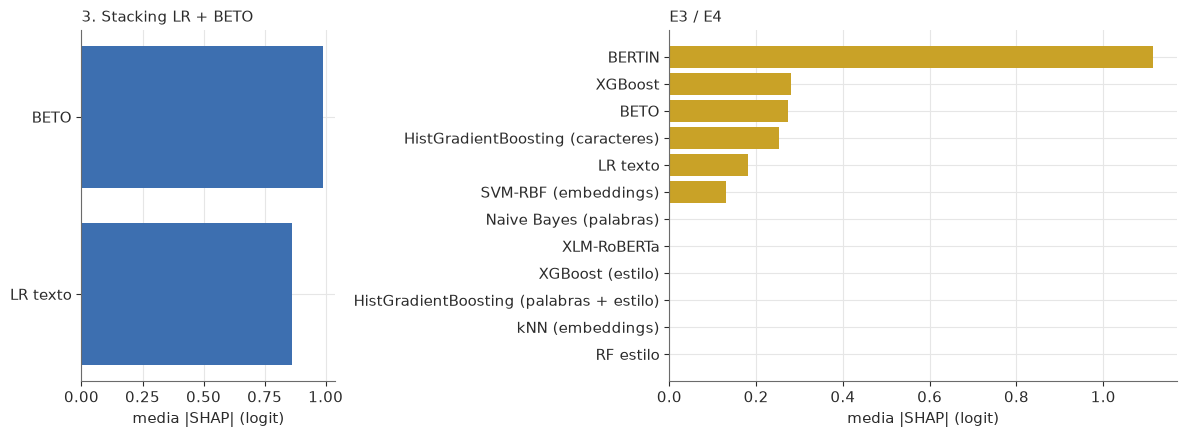

In [18]:
fig, ejes = plt.subplots(1, 2, figsize = (12, 4.5), gridspec_kw = {'width_ratios': [1, 2]})
for ax, nombre, color in [(ejes[0], '3. Stacking LR + BETO', '#3D6FB0'), (ejes[1], 'E3 / E4', '#c9a227')]:
    datos = importancias[importancias['meta-modelo'] == nombre].sort_values('media |SHAP|')
    ax.barh(datos['base'], datos['media |SHAP|'], color = color)
    ax.set_xlabel('media |SHAP| (logit)')
    ax.set_title(nombre, fontsize = 11)
fig.tight_layout()
guardar(fig, '7_1_finalistas_shap_bases')
plt.show()

**Qué se observa.**

* **La descomposición es exacta:** valor base + suma de SHAP reproduce el logit de cada noticia del test (diferencia máxima 0.0054 en el sistema 3, por el ajuste del optimizador, y 0.0002 en E3).
* **En el sistema 3, BETO y la LR se reparten la decisión** (Tabla 7.1): BETO aporta el 53.4 % de la importancia (media |SHAP| 0.990) y la LR el 46.6 % (0.864). Es un ensamble de verdad, no un modelo dominado por una base.
* **En E3, BERTIN aporta la mitad** (50.0 %, media |SHAP| 1.114). Le siguen XGBoost (12.5 %), BETO (12.3 %), HistGradientBoosting de caracteres (11.3 %), la LR (8.1 %) y el SVM (5.8 %). Naive Bayes casi no aporta (0.014 %) y cinco bases aportan exactamente 0.

**El sistema 3 combina dos lecturas distintas del texto en partes casi iguales. E3 y E4 dependen sobre todo de BERTIN, así que heredan su advertencia de contaminación de estilo.**

<a id="seccion-8"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 8: Qué palabras empujan cada predicción (LIME y SHAP de la LR)</span></div>

> **Qué se hace:** explicamos seis noticias del test elegidas con una regla fija (una de cada tipo de acierto y de error). Para cada una mostramos: qué base empujó hacia *Fake* o *True* (SHAP exacto), qué palabras movieron la predicción del sistema completo (LIME, calculado por `finalistas_lime.py`) y qué palabras pesaron en la LR de texto (SHAP exacto de un modelo lineal).
>
> **Qué se espera ver:** que el sistema completo y la LR coincidan en parte de las palabras, y que BETO/BERTIN expliquen los casos que la LR sola no ve.

#### Glosario de la sección
* **LIME** (Ribeiro et al., 2016): crea muchas versiones de la noticia quitando palabras al azar, ve cómo cambia la probabilidad del sistema completo y ajusta una regresión lineal local. El peso de cada palabra dice cuánto empuja hacia *Fake* (positivo) o hacia *True* (negativo) **en esa noticia**. Su R² dice qué tan bien la aproximación lineal imita al sistema cerca de esa noticia.
* **Por qué LIME y no SHAP para las palabras del sistema completo:** pasar por los transformers miles de versiones de cada noticia es caro; LIME necesitó 1,000 versiones por noticia. Para la LR de texto sí se puede SHAP exacto, porque es lineal.
* **E3 y E4 comparten explicación:** tienen la misma probabilidad; E4 solo cambia el corte.

**Tabla 8.1.** Noticias explicadas, probabilidad de cada finalista y R² local de LIME. También se verifica que las bases reentrenadas por `finalistas_lime.py` reproduzcan las probabilidades guardadas.

In [19]:
resumen_lime = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, 'finalistas_lime_resumen.csv'))
explicaciones = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, 'finalistas_lime.csv'))
verificacion_lime = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, 'finalistas_lime_verificacion.csv'))
print('Diferencia máxima entre las bases reentrenadas y las guardadas (texto original):')
display(verificacion_lime.groupby('base')['diferencia'].apply(lambda d: d.abs().max()).round(4).to_frame('diferencia máxima'))
noticias = resumen_lime.pivot_table(index = ['caso', 'id_unico', 'palabras en la noticia'], columns = 'sistema',
                                    values = ['prob de fake (texto completo)', 'R² local de LIME']).round(3)
noticias.columns = [f'{a} · {b}' for a, b in noticias.columns]
noticias = noticias.reset_index()
noticias.insert(2, 'clase real', prueba.set_index('id_unico').loc[noticias['id_unico'], 'Category'].values)
noticias

Diferencia máxima entre las bases reentrenadas y las guardadas (texto original):


,diferencia máxima
base,
BERTIN,0.0027
BETO,0.0088
HistGradientBoosting (caracteres),0.0000
LR texto,0.0000
Naive Bayes (palabras),0.0000
SVM-RBF (embeddings),0.0001
XGBoost,0.0000


,caso,id_unico,clase real,palabras en la noticia,R² local de LIME · 3. Stacking LR (LR + BETO),R² local de LIME · E3 / E4 (pesos no negativos),prob de fake (texto completo) · 3. Stacking LR (LR + BETO),prob de fake (texto completo) · E3 / E4 (pesos no negativos)
0,falsa detectada por los tres,tes_552,Fake,263,0.316,0.606,0.979,0.977
1,falsa larga detectada por los tres,tes_257,Fake,672,0.284,0.457,0.906,0.899
2,falsa que E4 detecta y el sistema 3 no,tes_6,Fake,123,0.656,0.704,0.474,0.861
3,falsa que ninguno detecta,tes_111,Fake,764,0.822,0.803,0.084,0.063
4,verdadera que los tres aciertan,tes_146,True,1314,0.550,0.772,0.065,0.057
5,verdadera que los tres marcan como falsa,tes_142,True,274,0.285,0.427,0.962,0.962


**Figura 8.1.** SHAP exacto por base de cada noticia explicada (escala logit; positivo empuja hacia *Fake*).

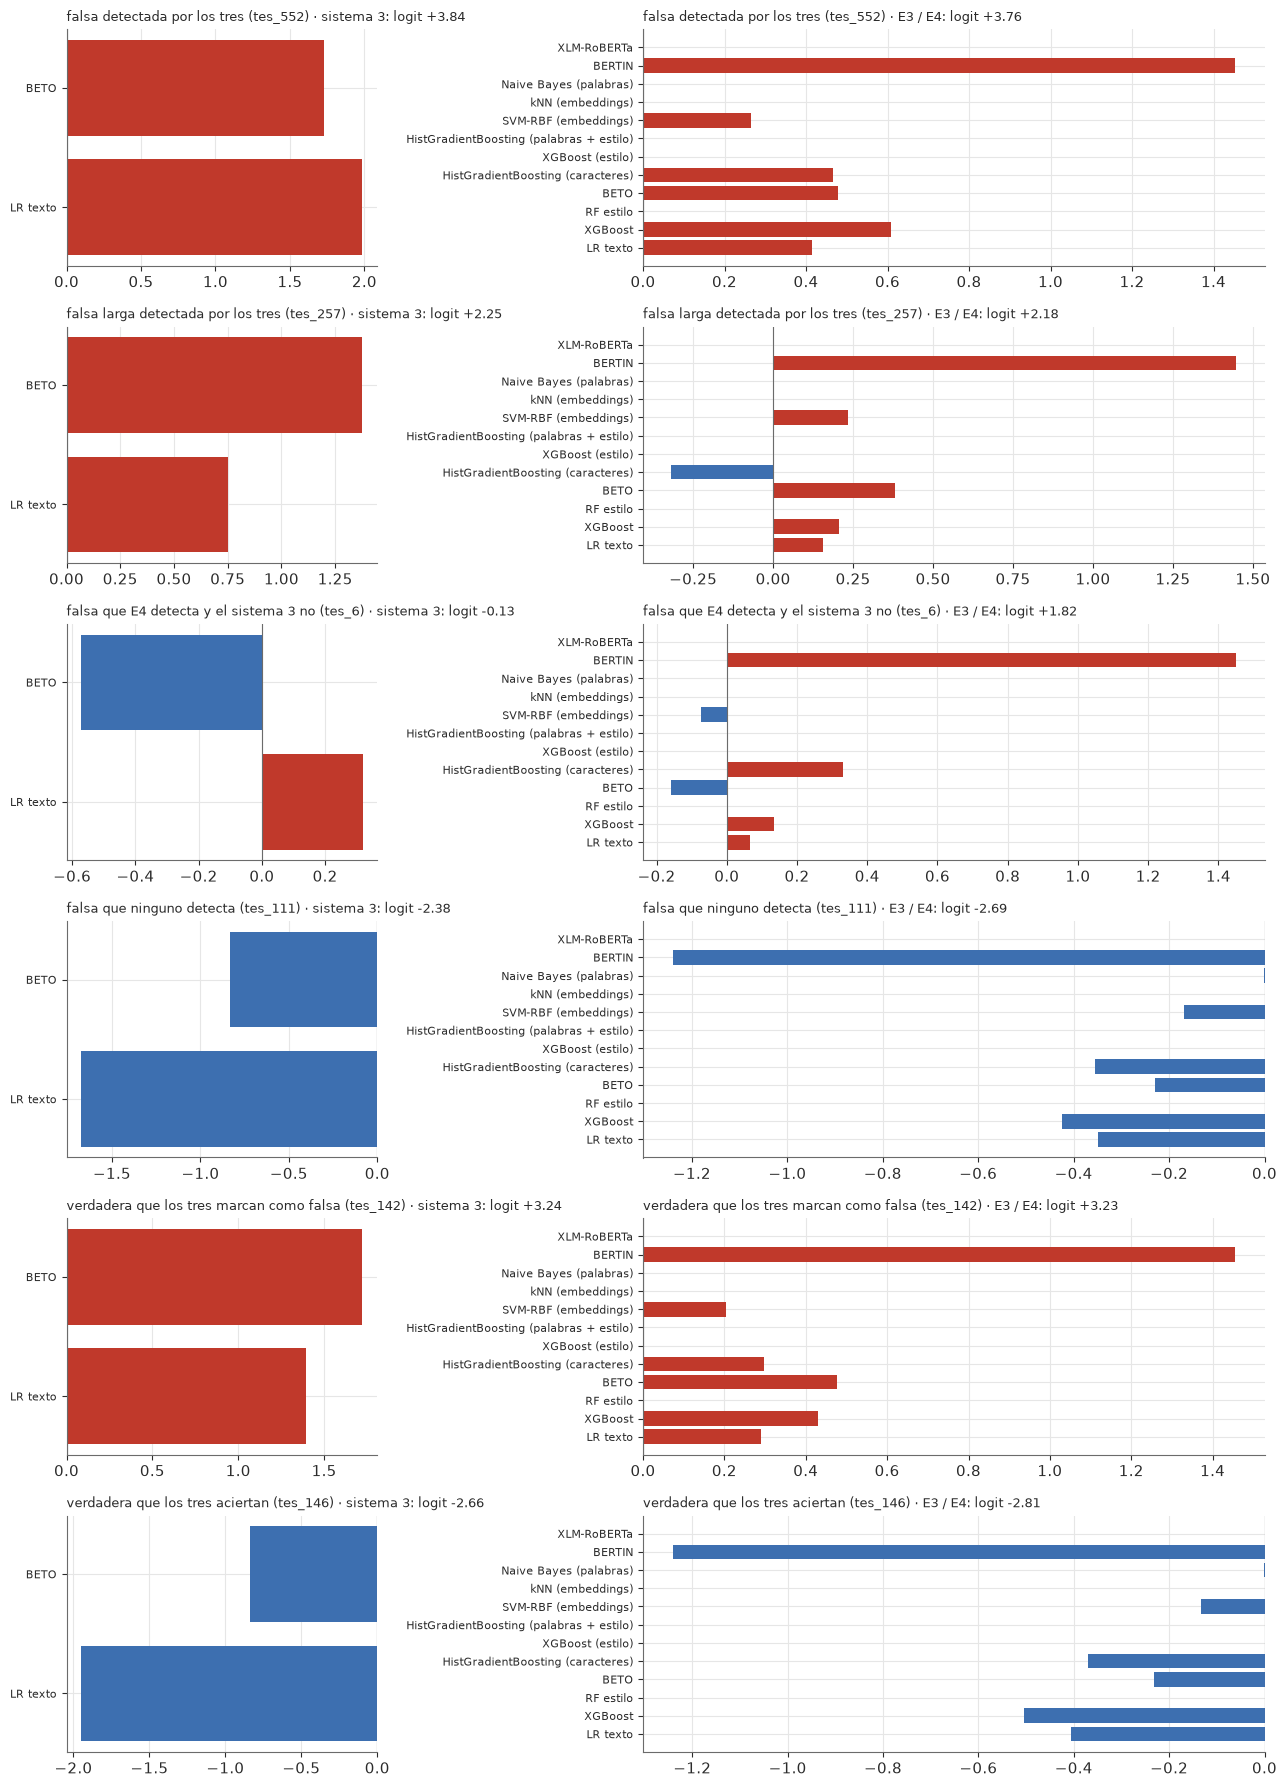

In [20]:
casos = resumen_lime.drop_duplicates('id_unico')[['id_unico', 'caso']].values
fig, ejes = plt.subplots(len(casos), 2, figsize = (13, 3.0 * len(casos)), gridspec_kw = {'width_ratios': [1, 2]})
for i, (id_unico, caso) in enumerate(casos):
    fila = int(np.where(prueba['id_unico'] == id_unico)[0][0])
    for ax, valores, bases, base_valor, titulo in [(ejes[i, 0], shap_3[fila], ENTRADAS_3, base_3, 'sistema 3'), (ejes[i, 1], shap_e3[fila], BASES, base_e3, 'E3 / E4')]:
        colores = []
        for v in valores:
            colores.append('#c0392b' if v > 0 else '#3D6FB0')
        ax.barh(bases, valores, color = colores)
        ax.axvline(0, color = TINTA_SUAVE, linewidth = 0.8)
        ax.set_title(f'{caso} ({id_unico}) · {titulo}: logit {base_valor + valores.sum():+.2f}', fontsize = 9)
        ax.tick_params(axis = 'y', labelsize = 8)
fig.tight_layout()
guardar(fig, '8_1_finalistas_shap_noticias')
plt.show()

**Figura 8.2.** LIME de punta a punta: las 12 palabras que más mueven la probabilidad de cada finalista en cada noticia (rojo: hacia *Fake*; azul: hacia *True*).

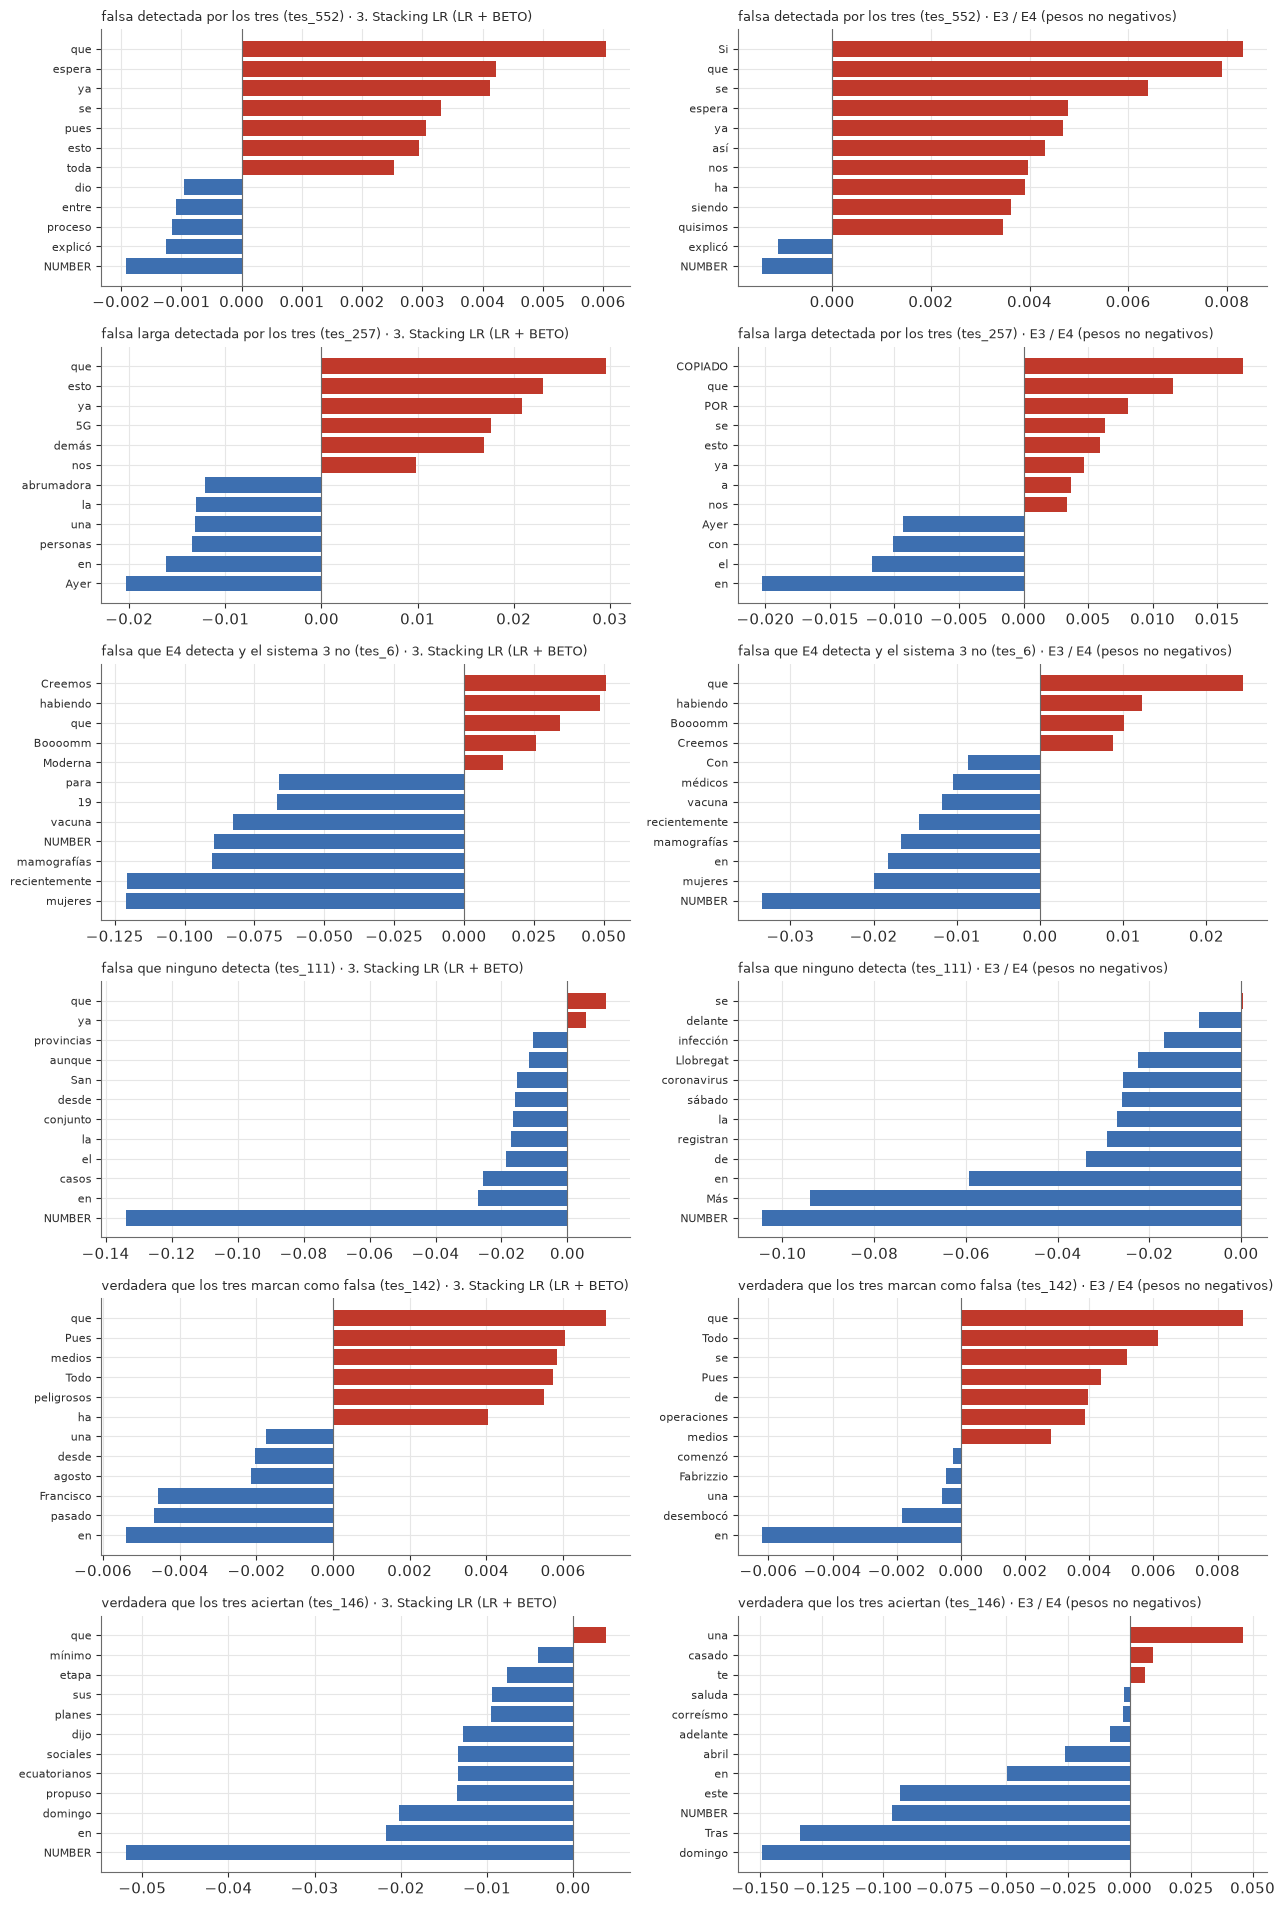

In [21]:
fig, ejes = plt.subplots(len(casos), 2, figsize = (13, 3.2 * len(casos)))
for i, (id_unico, caso) in enumerate(casos):
    for ax, sistema in zip(ejes[i], ['3. Stacking LR (LR + BETO)', 'E3 / E4 (pesos no negativos)']):
        datos = explicaciones[(explicaciones['id_unico'] == id_unico) & (explicaciones['sistema'] == sistema)].sort_values('peso hacia Fake')
        colores = []
        for v in datos['peso hacia Fake']:
            colores.append('#c0392b' if v > 0 else '#3D6FB0')
        ax.barh(datos['palabra'], datos['peso hacia Fake'], color = colores)
        ax.axvline(0, color = TINTA_SUAVE, linewidth = 0.8)
        ax.set_title(f'{caso} ({id_unico}) · {sistema}', fontsize = 9)
        ax.tick_params(axis = 'y', labelsize = 8)
fig.tight_layout()
guardar(fig, '8_2_finalistas_lime')
plt.show()

**Tabla 8.2.** SHAP exacto de la LR de texto (la base que comparten los tres finalistas) en las mismas noticias: los 8 atributos (palabras o n-gramas de caracteres) que más empujan hacia *Fake* y hacia *True*.

In [22]:
with open(os.path.join(uf.RUTA_RESULTADOS, 'seleccion_lineal.json'), encoding = 'utf-8') as f:
    config_lr = json.load(f)['elegida']
corpus = pd.read_parquet(os.path.join(uf.RUTA_PROCESADOS, 'corpus.parquet'))
textos_test = pd.read_parquet(os.path.join(uf.RUTA_PROCESADOS, 'test.parquet'), columns = ['id_unico', 'texto_sin_medio']).set_index('id_unico')
modelo_lr = uf.construir_pipeline(config_lr).fit(corpus, corpus['Category'])
signo = 1 if list(modelo_lr.classes_)[1] == 'Fake' else -1
coeficientes = signo * modelo_lr['clasificador'].coef_[0]
nombres = modelo_lr['representacion'].get_feature_names_out()
fondo = np.asarray(modelo_lr['representacion'].transform(corpus).mean(axis = 0)).ravel()
filas = []
for id_unico, caso in casos:
    x = modelo_lr['representacion'].transform(textos_test.loc[[id_unico]]).toarray().ravel()
    contribucion = coeficientes * (x - fondo)
    orden = np.argsort(contribucion)
    hacia_fake = []
    for j in orden[::-1][:8]:
        hacia_fake.append(nombres[j].split('__')[-1])
    hacia_true = []
    for j in orden[:8]:
        hacia_true.append(nombres[j].split('__')[-1])
    filas.append({'caso': caso, 'id_unico': id_unico, 'hacia Fake': ' · '.join(hacia_fake), 'hacia True': ' · '.join(hacia_true)})
pd.DataFrame(filas)

,caso,id_unico,hacia Fake,hacia True
0,falsa detectada por los tres,tes_552,ya · esto · espera que · pues · nos · en el · ...,proceso · un lugar · explicó · días de · local...
1,falsa larga detectada por los tres,tes_257,nos · nivel · para que · demás · pero · esto ·...,cinco · mucho más · entonces · tiene · china ·...
2,falsa que E4 detecta y el sistema 3 no,tes_6,de · en el · efectos · en la · que · normal · ...,mujeres · después · esas · contra · después de...
3,falsa que ninguno detecta,tes_111,igual · total de · finalmente · habitantes · e...,casos · en number · de number · number · numbe...
4,verdadera que los tres marcan como falsa,tes_142,esto · medios · number · mañana · eso · los me...,pasado · francisco · seis · la que · agosto · ...
5,verdadera que los tres aciertan,tes_146,llevó · conocido · finalmente · espera · unión...,domingo · electoral · en number · number de · ...


**Qué se observa.**

* **Las bases reentrenadas para LIME reproducen las guardadas** (Tabla 8.1): la diferencia máxima es 0.0000 en las bases deterministas y 0.0088 (BETO) y 0.0027 (BERTIN) en las de GPU. Así que LIME explica los mismos modelos que se evaluaron.
* **El caso que separa a los finalistas** es una falsa corta de 123 palabras sobre vacunas y mamografías (`tes_6`): el sistema 3 le da 0.474 y E3/E4 0.861.
  * En el sistema 3, **BETO** la empuja hacia *True* y la LR apenas hacia *Fake* (Figura 8.1). LIME señala que lo que la hace parecer verdadera es su registro informativo: "mujeres", "recientemente", "mamografías" y las cifras.
  * En E3, **BERTIN** la empuja con fuerza hacia *Fake*, con ayuda del HistGradientBoosting de caracteres, y eso supera el empuje de BETO.
* **La falsa que nadie detecta** (`tes_111`, 764 palabras) se explica por las cifras: el marcador `NUMBER` es lo que más la empuja hacia *True* en los dos sistemas. Es el patrón que se vio en el proyecto: las verdaderas citan más cifras, y una falsa larga con cifras pasa por verdadera.
* **La verdadera que los tres marcan como falsa** (`tes_142`) tiene un registro coloquial ("pues", "todo", "que"), y eso la empuja hacia *Fake*: el sistema confunde el tono con la falsedad.
* **La LR de texto (SHAP exacto, Tabla 8.2) coincide con LIME:** las cifras (`number`, "en number", "de number") y palabras de crónica ("domingo", "explicó") empujan hacia *True*; palabras coloquiales o de opinión ("esto", "pues", "ya", "nos") hacia *Fake*.
* **Ojo con la confianza de LIME:** su R² local va de 0.284 a 0.822 en el sistema 3 y de 0.427 a 0.803 en E3/E4. En las noticias con R² bajo, como la falsa larga (0.284), la aproximación por palabras sueltas explica poco, porque BETO y BERTIN leen el contexto y no palabras aisladas.

**Los tres finalistas deciden sobre todo por registro: tono coloquial = falsa; tono de crónica con cifras = verdadera. Funciona en la mayoría de los casos y falla justo cuando una falsa imita la crónica o una verdadera es coloquial.**

<a id="conclusiones"></a>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Conclusiones</span></div>

<a id="seccion-9"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 9: ¿Cuál elegir?</span></div>

> **Qué se hace:** resumimos los tres finalistas con todo lo anterior.
>
> **Qué se espera ver:** una recomendación con sus advertencias.

**¿Cuál elegir?** Depende de qué se quiera defender, porque en el test no se distinguen.

| | Sistema 3 | E3 | E4 |
|:--|:--|:--|:--|
| F1 de fake en CV | 0.7463 | 0.8116 | 0.813 |
| F1 de fake en el test | 0.7357 [0.690, 0.778] | 0.7496 [0.708, 0.789] | **0.7550** [0.715, 0.794] |
| Exactitud en el test | **0.7500** | 0.7430 | 0.7413 |
| Precisión / exhaustividad de fake (test) | **0.7804** / 0.6958 | 0.7309 / 0.7692 | 0.7170 / **0.7972** |
| Bases que necesita | LR + BETO (1 transformer) | 7 bases con peso (2 transformers) | igual que E3 |
| ¿Se fijó antes de ver su test? | **sí** | no | no |
| Advertencia | — | CV inflada por BERTIN | CV inflada por BERTIN |

**Recomendación:**

* **Reportar el sistema 3 como sistema final.** Es el que eligió el protocolo, su número del test es una estimación limpia y es mucho más simple (una LR y un transformer). También es el más preciso y el que más noticias acierta en total.
* **Reportar E4 como el mejor resultado exploratorio** (0.7550 en el test, el que más falsas detecta), con su advertencia: se diseñó después de ver el test y su ventaja en CV viene de BERTIN, que conocía el estilo de los sitios del corpus. Su diferencia con el sistema 3 (+0.019, IC [−0.019, +0.056]) no es significativa.
* **E3 queda como el paso intermedio** que muestra que el umbral de E4 aporta poco.

Si el equipo prefiere priorizar detectar falsas aunque haya más falsas alarmas (por ejemplo, para una herramienta que solo señala noticias para revisión humana), E4 es defendible, siempre que se reporte con su advertencia. Si se prioriza la confiabilidad del número reportado y la simplicidad, el sistema 3 (lámina 24: agregar complejidad solo si mejora la validación, y en el test no la mejora).

<a id="seccion-10"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 10: Referencias</span></div>

> **Qué se hace:** fuentes citadas.
>
> **Qué se espera ver:** referencias completas.

1. Ribeiro, M. T., Singh, S. y Guestrin, C. (2016). "Why Should I Trust You?": Explaining the Predictions of Any Classifier. En *KDD 2016* (LIME).
2. Lundberg, S. M. y Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. En *NeurIPS 2017* (SHAP).
3. Wolpert, D. H. (1992). Stacked generalization. *Neural Networks*, 5(2), 241–259.
4. Cañete, J., Chaperon, G., Fuentes, R., Ho, J.-H., Kang, H. y Pérez, J. (2020). Spanish Pre-Trained BERT Model and Evaluation Data. En *PML4DC at ICLR 2020* (BETO).
5. De la Rosa, J. et al. (2022). BERTIN: Efficient Pre-Training of a Spanish Language Model using Perplexity Sampling. *Procesamiento del Lenguaje Natural*, 68, 13–23.
6. Nocedal, J. y Wright, S. J. (2006). *Numerical Optimization* (2.ª ed.). Springer (L-BFGS).
7. Gómez-Adorno, H., Posadas-Durán, J. P., Bel Enguix, G. y Porto Capetillo, C. (2021). Overview of FakeDeS at IberLEF 2021. *Procesamiento del Lenguaje Natural*, 67, 223–231.